# Лабораторная работа №4. Случайный лес

**Цель:** провести исследование случайного леса на задачах классификации (Dota 2) и регрессии (шахматный эндшпиль KRKPA7): бейзлайн `sklearn`, улучшение через проверку гипотез, собственная реализация и сравнение (пункты 2–4 ЛР №1).

Наборы данных, постановка задач и обоснование метрик — в разделе 1 ЛР №1 (`lab1_knn.ipynb`). Метрики: классификация — **ROC-AUC** (основная), accuracy, F1; регрессия — **R²** (основная), RMSE, MAE.

## 0. Подготовка окружения

Импортируем библиотеки и общий пакет `mllab` из корня репозитория. В `mllab` лежат:
загрузчики данных (`mllab.data`), генераторы признаков (`mllab.features`), функции подсчёта метрик и журнал результатов (`mllab.metrics`), а также собственные реализации алгоритмов (`mllab.knn`, `mllab.linear`, `mllab.tree`, `mllab.forest`, `mllab.boosting`).
Предупреждения отключаем, чтобы не засорять вывод; для `Pipeline` включаем дисковый кэш (`.cache/`), чтобы тяжёлые преобразования признаков не пересчитывались в каждом прогоне кросс-валидации.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import inspect

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Code, display
from joblib import Memory
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler

import mllab
from mllab.data import RANDOM_STATE, load_chess, load_dota
from mllab.features import ChessFeatures, DotaFeatures
from mllab.metrics import ResultsLog, compare_cv, cv_report, evaluate

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_colwidth", 120)
memory = Memory(ROOT / ".cache", verbose=0)

Загружаем данные (подробное описание и обоснование выбора — в разделе 1 ЛР №1):
* **классификация** — *Dota 2 Games Results*: используем официальное разбиение UCI на train (92 650 матчей) и test (10 294 матча); целевая переменная `1` — победила команда 1;
* **регрессия** — *Chess KR vs KP (KRKPA7)*: стратифицированное разбиение 80/20 (`random_state=42`); целевая переменная `1.0` — белые выигрывают, `0.0` — нет; модель предсказывает непрерывную «оценку позиции».

Гиперпараметры подбираем только на train через 5-кратную кросс-валидацию (`StratifiedKFold` для классификации, `KFold` для регрессии); test используется только для финальной оценки.

In [2]:
X_cls_train, X_cls_test, y_cls_train, y_cls_test = load_dota()
X_reg_train, X_reg_test, y_reg_train, y_reg_test = load_chess()

cv_cls = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Классификация (Dota 2):", X_cls_train.shape, X_cls_test.shape)
print("Регрессия (шахматы KRKPA7):", X_reg_train.shape, X_reg_test.shape)

log = ResultsLog(lab=4, algorithm="RandomForest")

Классификация (Dota 2): (92650, 116) (10294, 116)
Регрессия (шахматы KRKPA7): (2556, 36) (640, 36)


## 2. Создание бейзлайна и оценка качества

Бейзлайн — `RandomForestClassifier` и `RandomForestRegressor` из `sklearn` с параметрами по умолчанию: 100 деревьев, бутстрэп-выборки, деревья растут до чистых листьев; в классификаторе в каждом узле рассматривается √d случайных признаков, в регрессоре — все признаки (`max_features=1.0`). Обучение распараллелено на все ядра (`n_jobs=-1`).

In [3]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

baseline_cls = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
baseline_reg = make_pipeline(ChessFeatures(), RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))

log.add("classification", "sklearn baseline",
        evaluate(baseline_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "sklearn baseline",
        evaluate(baseline_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
display(log.table("classification"), log.table("regression"))

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.6087,0.5786,0.6374,3.8917,0.2205


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.9864,0.0583,0.0095,0.2475,0.0595


<!-- lab4_baseline -->
**Вывод по бейзлайну.**
* *Классификация:* случайный лес из 100 полных деревьев даёт ROC-AUC = 0.609 и accuracy = 0.579 — намного лучше одиночного дерева (0.518): усреднение 100 декоррелированных переобученных деревьев резко уменьшает дисперсию. Но до логистической регрессии (0.634) лес не дотягивает: деревья по-прежнему растут до чистых листьев.
* *Регрессия:* R² = 0.986, MAE = 0.0095 — на уровне одиночного дерева (0.9875). MAE даже выше, чем у дерева: усреднение даёт дробные оценки на спорных позициях вместо точных 0/1.

## 3. Улучшение бейзлайна

### 3.1. Гипотезы

**Классификация (Dota 2):**
* **H1. Новые признаки.** Как и для одиночного дерева, компактные признаки драфта (win rate, синергия, контрпики) должны дать лесу более информативные разбиения, чем 113 разреженных индикаторов героев.
* **H2. Минимальный размер листа.** Деревья, выращенные до чистых листьев, на шумных данных выдают оценки вероятности, близкие к 0/1; усреднение по 100 деревьям их сглаживает, но крупные листья (`min_samples_leaf`) должны дать более точные вероятности.
* **H3. Число признаков в узле (`max_features`).** Меньше признаков — сильнее декорреляция деревьев, больше — сильнее каждое дерево.
* **H4. Число деревьев.** Рост числа деревьев уменьшает дисперсию ансамбля, качество должно выходить на плато.

**Регрессия (шахматы):**
* **H1. Число деревьев** (100 → 300 → 500).
* **H2. Число признаков в узле (`max_features`).** Правила эндшпиля опираются на несколько ключевых признаков; если в узле их нет среди кандидатов, разбиение получается слабым — проверим, что лучше: бэггинг (все признаки) или случайные подпространства.
* **H3. Попарные взаимодействия признаков** (как в ЛР №2).
* **H4. Совместный подбор гиперпараметров** на кросс-валидации.

### 3.2. Проверка гипотез для классификации

**H1.** Сравниваем лес на исходных признаках и на признаках драфта (300 деревьев, `min_samples_leaf=100`, чтобы сравнение не зависело от переобучения отдельных деревьев).

In [4]:
def forest_cls(**params):
    return RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, **params)

h1_cls = compare_cv({
    "исходные признаки": forest_cls(min_samples_leaf=100),
    "индикаторы + статистики": make_pipeline(DotaFeatures(meta="drop", drop_constant=True, synergy=True),
                                             forest_cls(min_samples_leaf=100)),
    "только статистики (7 признаков)": make_pipeline(DotaFeatures(meta="drop", heroes="none", synergy=True),
                                                     forest_cls(min_samples_leaf=100)),
}, X_cls_train, y_cls_train, cv_cls, "roc_auc", n_jobs=1)
h1_cls

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
исходные признаки,0.6139,0.0045,0.6478,4.1886
индикаторы + статистики,0.6376,0.0037,0.6842,12.4448
только статистики (7 признаков),0.6356,0.0042,0.6811,13.5219


<!-- lab4_h1_cls -->
**H1 подтверждена.** Признаки драфта повышают ROC-AUC на CV с 0.614 до 0.636–0.638. Вариант «индикаторы + статистики» немного лучше компактного (0.6376 против 0.6356), но разница меньше разброса по фолдам (0.004). Для подбора гиперпараметров используем компактное представление из 7 признаков — как в ЛР №1 и №3, это делает сравнение алгоритмов единообразным.

**H2 и H3.** Подбираем по сетке минимальный размер листа и число признаков в узле на компактных признаках драфта (300 деревьев).

In [5]:
pipe_cls = Pipeline([
    ("features", DotaFeatures(meta="drop", heroes="none", synergy=True)),
    ("model", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)),
], memory=memory)
search_cls = GridSearchCV(pipe_cls, {
    "model__min_samples_leaf": [1, 50, 200, 500],
    "model__max_features": ["sqrt", 0.5, 1.0],
}, cv=cv_cls, scoring="roc_auc", n_jobs=-1).fit(X_cls_train, y_cls_train)
print("Лучшие параметры:", search_cls.best_params_)
report = cv_report(search_cls, top=12)
report

Лучшие параметры: {'model__max_features': 'sqrt', 'model__min_samples_leaf': 500}


,model__max_features,model__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
0,sqrt,500,0.6372,0.0041,1
1,0.5000,500,0.6371,0.0041,2
2,sqrt,200,0.6367,0.0041,3
3,1.0000,500,0.6367,0.0041,4
4,0.5000,200,0.6364,0.0042,5
5,1.0000,200,0.6355,0.0042,6
6,sqrt,50,0.6338,0.0044,7
7,0.5000,50,0.6332,0.0046,8
8,1.0000,50,0.6314,0.0044,9
9,sqrt,1,0.6091,0.0037,10


Визуализируем результаты поиска: ROC-AUC на кросс-валидации в зависимости от размера листа для каждого значения `max_features`.

max_features,0.5,1.0,sqrt
model__min_samples_leaf,,,
1,0.6076,0.6051,0.6091
50,0.6332,0.6314,0.6338
200,0.6364,0.6355,0.6367
500,0.6371,0.6367,0.6372


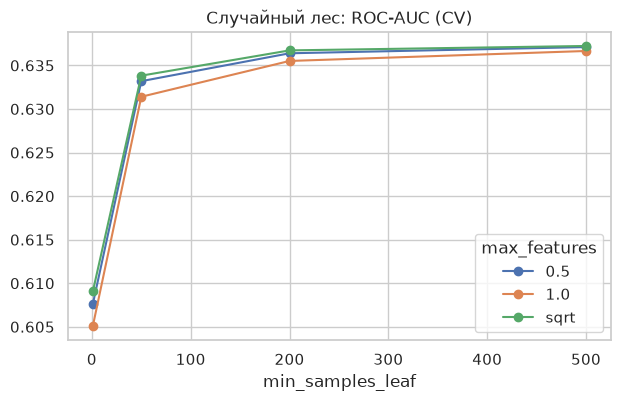

In [6]:
pivot = report.assign(max_features=report["model__max_features"].astype(str)).pivot_table(
    index="model__min_samples_leaf", columns="max_features", values="mean_test_score")
ax = pivot.plot(marker="o", figsize=(7, 4), title="Случайный лес: ROC-AUC (CV)")
ax.set_xlabel("min_samples_leaf")
pivot

<!-- lab4_h23_cls -->
**H2 подтверждена, H3 — слабо.** Размер листа — ключевой параметр: при листьях из 1 объекта ROC-AUC на CV = 0.605–0.609, при 50 — 0.633, при 200–500 — 0.636–0.637. `max_features` влияет слабо (различия ≤ 0.002), лучше всего `sqrt` (2 случайных признака из 7 в каждом узле — максимальная декорреляция деревьев). Оптимум — `min_samples_leaf = 500`, `max_features = "sqrt"` (0.6372); значение на границе сетки, но рост от 200 к 500 составляет всего 0.0005 — кривая вышла на плато.

**H4.** Строим зависимость качества от числа деревьев для лучшей конфигурации. Чтобы не обучать лес заново для каждого размера, используем `warm_start=True`: деревья добавляются к уже обученным, а качество оцениваем по out-of-bag объектам (для каждого объекта усредняются только деревья, не видевшие его при обучении) — это бесплатная оценка обобщающей способности без отдельной валидации.

,OOB ROC-AUC
25,0.6362
50,0.6370
100,0.6372
200,0.6374
300,0.6374
500,0.6374


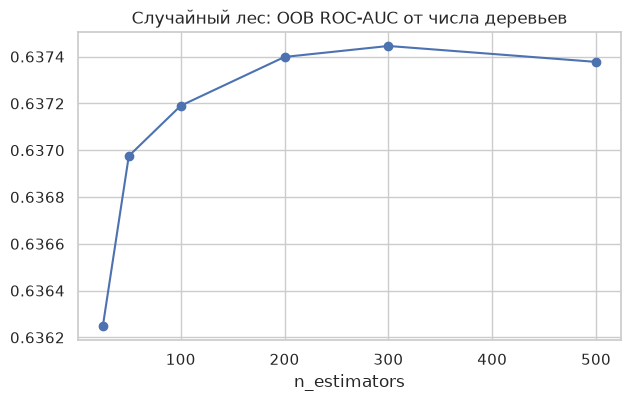

In [7]:
from sklearn.metrics import roc_auc_score

best_cls = search_cls.best_params_
features_cls = DotaFeatures(meta="drop", heroes="none", synergy=True)
F_train = features_cls.fit_transform(X_cls_train, y_cls_train)
growing = RandomForestClassifier(n_estimators=25, warm_start=True, oob_score=True, random_state=RANDOM_STATE,
                                 n_jobs=-1, min_samples_leaf=best_cls["model__min_samples_leaf"],
                                 max_features=best_cls["model__max_features"])
oob_curve = {}
for n_trees in [25, 50, 100, 200, 300, 500]:
    growing.set_params(n_estimators=n_trees).fit(F_train, y_cls_train)
    oob_curve[n_trees] = roc_auc_score(y_cls_train, growing.oob_decision_function_[:, 1])
ax = pd.Series(oob_curve).plot(marker="o", figsize=(7, 4), title="Случайный лес: OOB ROC-AUC от числа деревьев")
ax.set_xlabel("n_estimators")
pd.Series(oob_curve, name="OOB ROC-AUC").to_frame()

<!-- lab4_h4_cls -->
**H4 подтверждена.** OOB ROC-AUC растёт с 0.6362 (25 деревьев) до 0.6374 (200 деревьев) и дальше не меняется: после ≈200 деревьев дисперсия ансамбля перестаёт уменьшаться. Выбранных 300 деревьев достаточно с запасом; OOB-оценка (0.637) согласуется с кросс-валидацией.

### 3.3. Проверка гипотез для регрессии

**H1, H2, H3.** Сравниваем число деревьев, `max_features` и добавление взаимодействий (R² на кросс-валидации).

In [8]:
def forest_reg(features=None, **params):
    return make_pipeline(features or ChessFeatures(),
                         RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **params))

h_reg = compare_cv({
    "100 деревьев (бейзлайн)": forest_reg(),
    "300 деревьев": forest_reg(n_estimators=300),
    "500 деревьев": forest_reg(n_estimators=500),
    "max_features=0.5": forest_reg(n_estimators=300, max_features=0.5),
    "max_features=0.3": forest_reg(n_estimators=300, max_features=0.3),
    "max_features=sqrt": forest_reg(n_estimators=300, max_features="sqrt"),
    "+ взаимодействия, max_features=0.3": forest_reg(ChessFeatures(interactions=True), n_estimators=300,
                                                      max_features=0.3),
}, X_reg_train, y_reg_train, cv_reg, "r2", n_jobs=1)
h_reg

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
100 деревьев (бейзлайн),0.9800,0.0078,0.9969,0.2077
300 деревьев,0.9805,0.0079,0.9971,0.5770
500 деревьев,0.9805,0.0076,0.9971,0.9127
max_features=0.5,0.9740,0.0083,0.9964,0.5668
max_features=0.3,0.9634,0.0085,0.9947,0.5843
max_features=sqrt,0.9407,0.0096,0.9915,0.5551
"+ взаимодействия, max_features=0.3",0.9751,0.0061,0.9963,0.4727


<!-- lab4_h123_reg -->
**H1 подтверждена слабо, H2 и H3 не подтверждены.**
* Рост числа деревьев с 100 до 300 даёт +0.0005 R² (0.9800 → 0.9805), дальше — без изменений.
* Ограничение числа признаков в узле **ухудшает** качество: 0.974 (50 %), 0.963 (30 %), 0.941 (√d). Правила эндшпиля опираются на несколько ключевых признаков (`rimmx`, `bxqsq`, `wknck`, …), и если их нет среди кандидатов, дерево делает заведомо худшее разбиение. Для этой задачи лучше чистый бэггинг.
* Взаимодействия частично компенсируют потерю признаков (0.975 против 0.963 при `max_features = 0.3`), но до бэггинга на исходных признаках не дотягивают.

**H4.** Совместный подбор числа деревьев, `max_features` и размера листа.

In [9]:
pipe_reg = Pipeline([
    ("features", ChessFeatures()),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1)),
])
search_reg = GridSearchCV(pipe_reg, {
    "model__n_estimators": [300, 500],
    "model__max_features": [1.0, 0.7, 0.5],
    "model__min_samples_leaf": [1, 2],
}, cv=cv_reg, scoring="r2", n_jobs=-1).fit(X_reg_train, y_reg_train)
print("Лучшие параметры:", search_reg.best_params_)
cv_report(search_reg)

Лучшие параметры: {'model__max_features': 1.0, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}


,model__max_features,model__min_samples_leaf,model__n_estimators,mean_test_score,std_test_score,rank_test_score
0,1.0000,1,300,0.9805,0.0079,1
1,1.0000,1,500,0.9805,0.0076,2
2,0.7000,1,300,0.9788,0.0076,3
3,0.7000,1,500,0.9787,0.0076,4
4,0.5000,1,300,0.9740,0.0083,5
5,0.5000,1,500,0.9739,0.0075,6
6,1.0000,2,500,0.9700,0.0076,7
7,1.0000,2,300,0.9697,0.0078,8
8,0.7000,2,500,0.9681,0.0071,9
9,0.7000,2,300,0.9679,0.0074,10


<!-- lab4_h4_reg -->
**H4.** Лучшая конфигурация по CV — 300 деревьев, все признаки в узле, листья из 1 объекта (R² = 0.9805); `min_samples_leaf = 2` ухудшает качество (0.970) по той же причине, что и для одиночного дерева, — в данных нет шума.

### 3.4. Улучшенный бейзлайн

* **классификация** — компактные признаки драфта → `RandomForestClassifier` (300 деревьев) с подобранными `min_samples_leaf` и `max_features`;
* **регрессия** — лучшая по кросс-валидации конфигурация леса.

In [10]:
from sklearn.base import clone

improved_cls = clone(search_cls.best_estimator_).set_params(model__n_jobs=-1)
improved_reg = clone(search_reg.best_estimator_).set_params(model__n_jobs=-1)

log.add("classification", "sklearn improved",
        evaluate(improved_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "sklearn improved",
        evaluate(improved_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
display(log.table("classification"), log.table("regression"))

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.6087,0.5786,0.6374,3.8917,0.2205
sklearn improved,0.6387,0.5984,0.6356,4.1057,0.2505


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.9864,0.0583,0.0095,0.2475,0.0595
sklearn improved,0.9872,0.0566,0.0090,0.5898,0.1423


<!-- lab4_improved -->
**Сравнение улучшенного бейзлайна с бейзлайном (test).**
* *Классификация:* ROC-AUC 0.609 → **0.639** (+0.030), accuracy 0.579 → 0.598, F1 практически без изменений (0.637 → 0.636). Время обучения почти не изменилось: деревьев втрое больше, но они намного меньше.
* *Регрессия:* R² 0.9864 → 0.9872, RMSE 0.058 → 0.057 — прирост в пределах шума; бейзлайн леса для шахмат уже близок к оптимальному.

## 4. Имплементация алгоритма машинного обучения

### 4.1. Собственная реализация случайного леса

Реализация — `mllab/forest.py`, базовые деревья — собственные `mllab.DecisionTreeClassifier/Regressor` из ЛР №3:
* признаки один раз переводятся в корзины (`Binner`), и все деревья работают с одной и той же бинаризованной матрицей — бутстрэп-выборка передаётся в дерево как массив индексов (с повторами), без копирования данных;
* каждое дерево получает собственный seed: от него зависят и бутстрэп-выборка, и случайный выбор `max_features` признаков в каждом узле;
* деревья обучаются параллельно через `joblib` (`n_jobs`);
* классификатор усредняет вероятности классов по деревьям, регрессор — предсказания; важность признаков — среднее важностей деревьев.

Выводим исходный код реализации.

In [11]:
display(Code(inspect.getsource(mllab.forest), language="python"))

import numpy as np
from joblib import Parallel, delayed
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin

from .tree import Binner, DecisionTreeClassifier, DecisionTreeRegressor


def _grow(tree, Xg, target, binner, seed, bootstrap, max_samples, classes):
    rng = np.random.default_rng(seed)
    n = len(Xg)
    size = n if max_samples is None else max(1, int(max_samples * n))
    sample_idx = rng.integers(0, n, size) if bootstrap else None
    if classes is not None:
        tree.classes_, tree.n_classes_ = classes, len(classes)
    return tree._fit_binned(Xg, target, binner, sample_idx)


class _BaseForest(BaseEstimator):
    _tree_class = None

    def __init__(self, n_estimators=100, criterion=None, max_depth=None, min_samples_split=2,
                 min_samples_leaf=1, max_features="sqrt", bootstrap=True, max_samples=None,
                 max_bins=255, n_jobs=None, random_state=None):
        self.n_estimators = n_estimators
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.bootstrap = bootstrap
        self.max_samples = max_samples
        self.max_bins = max_bins
        self.n_jobs = n_jobs
        self.random_state = random_state

    def _make_tree(self, seed):
        params = dict(max_depth=self.max_depth, min_samples_split=self.min_samples_split,
                      min_samples_leaf=self.min_samples_leaf, max_features=self.max_features,
                      max_bins=self.max_bins, random_state=seed)
        if self.criterion is not None:
            params["criterion"] = self.criterion
        return self._tree_class(**params)

    def _fit_forest(self, X, target, classes=None):
        binner = Binner(self.max_bins).fit(X)
        Xg = binner.transform(X)
        seeds = np.random.default_rng(self.random_state).integers(0, 2 ** 31 - 1, self.n_estimators)
        self.estimators_ = Parallel(n_jobs=self.n_jobs)(
            delayed(_grow)(self._make_tree(int(s)), Xg, target, binner, int(s), self.bootstrap,
                           self.max_samples, classes)
            for s in seeds
        )
        self.n_features_in_ = Xg.shape[1]
        self.feature_importances_ = np.mean([t.feature_importances_ for t in self.estimators_], axis=0)
        return self


class RandomForestClassifier(_BaseForest, ClassifierMixin):
    _tree_class = DecisionTreeClassifier

    def fit(self, X, y):
        self.classes_, encoded = np.unique(y, return_inverse=True)
        self.n_classes_ = len(self.classes_)
        return self._fit_forest(X, encoded.astype(np.intp), self.classes_)

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        return np.mean([tree.predict_proba(X) for tree in self.estimators_], axis=0)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


class RandomForestRegressor(_BaseForest, RegressorMixin):
    _tree_class = DecisionTreeRegressor

    def __init__(self, n_estimators=100, criterion=None, max_depth=None, min_samples_split=2,
                 min_samples_leaf=1, max_features=1.0, bootstrap=True, max_samples=None,
                 max_bins=255, n_jobs=None, random_state=None):
        super().__init__(n_estimators, criterion, max_depth, min_samples_split, min_samples_leaf,
                         max_features, bootstrap, max_samples, max_bins, n_jobs, random_state)

    def fit(self, X, y):
        return self._fit_forest(X, np.asarray(y, dtype=float))

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return np.mean([tree.predict(X) for tree in self.estimators_], axis=0)

Обучаем собственный лес с параметрами бейзлайна (100 полных деревьев, √d признаков для классификации, все признаки для регрессии).

In [12]:
custom_cls = mllab.RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
custom_reg = make_pipeline(ChessFeatures(),
                           mllab.RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))

log.add("classification", "custom",
        evaluate(custom_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "custom",
        evaluate(custom_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
display(log.table("classification").loc[["sklearn baseline", "custom"]],
        log.table("regression").loc[["sklearn baseline", "custom"]])

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.6087,0.5786,0.6374,3.8917,0.2205
custom,0.6069,0.5778,0.6275,47.9906,0.9774


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.9864,0.0583,0.0095,0.2475,0.0595
custom,0.9890,0.0523,0.0080,0.2578,0.0294


Случайный лес — стохастический алгоритм, поэтому сравнивать реализации по одному запуску некорректно. Оценим разброс качества по нескольким seed на шахматной регрессии для обеих реализаций.

In [13]:
from sklearn.metrics import r2_score

reg_features = ChessFeatures().fit(X_reg_train)
A_train, A_test = reg_features.transform(X_reg_train), reg_features.transform(X_reg_test)
seeds = range(5)
spread = pd.DataFrame({
    "sklearn": [r2_score(y_reg_test, RandomForestRegressor(random_state=s, n_jobs=-1)
                         .fit(A_train, y_reg_train).predict(A_test)) for s in seeds],
    "custom": [r2_score(y_reg_test, mllab.RandomForestRegressor(random_state=s, n_jobs=-1)
                        .fit(A_train, y_reg_train).predict(A_test)) for s in seeds],
}, index=pd.Index(seeds, name="seed"))
display(spread.T)
spread.agg(["mean", "std"])

seed,0,1,2,3,4
sklearn,0.9878,0.9877,0.9888,0.9868,0.9873
custom,0.9880,0.9859,0.9882,0.9878,0.9878


,sklearn,custom
mean,0.9877,0.9875
std,0.0007,0.0009


<!-- lab4_custom -->
**Вывод по собственной реализации.**
* *Классификация:* ROC-AUC 0.607 против 0.609 у `sklearn`, accuracy 0.578 против 0.579. Различия объясняются другими случайными бутстрэп-выборками и подмножествами признаков (свой генератор случайных чисел) и различием в разрешении равенств при выборе разбиений.
* *Регрессия:* по одному запуску собственный лес даже лучше (R² 0.989 против 0.986), но эксперимент с 5 seed показывает, что реализации статистически неразличимы: 0.9877 ± 0.0007 у `sklearn` и 0.9875 ± 0.0009 у собственной. Различие одиночных запусков — случайность.
* Полные деревья на Dota 2 собственная реализация строит в ≈12 раз дольше (48 с против 3.9 с даже при параллельном обучении): каждое из 100 деревьев содержит десятки тысяч узлов, обрабатываемых в цикле Python.

### 4.2. Собственная реализация + техники улучшенного бейзлайна

Используем собственный лес в конвейерах улучшенного бейзлайна с теми же признаками и гиперпараметрами.

In [14]:
best_reg = search_reg.best_params_

custom_improved_cls = Pipeline([
    ("features", DotaFeatures(meta="drop", heroes="none", synergy=True)),
    ("model", mllab.RandomForestClassifier(n_estimators=300,
                                           min_samples_leaf=best_cls["model__min_samples_leaf"],
                                           max_features=best_cls["model__max_features"],
                                           random_state=RANDOM_STATE, n_jobs=-1)),
], memory=memory)
custom_improved_reg = Pipeline([
    ("features", ChessFeatures()),
    ("model", mllab.RandomForestRegressor(n_estimators=best_reg["model__n_estimators"],
                                          max_features=best_reg["model__max_features"],
                                          min_samples_leaf=best_reg["model__min_samples_leaf"],
                                          random_state=RANDOM_STATE, n_jobs=-1)),
])

log.add("classification", "custom improved",
        evaluate(custom_improved_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "custom improved",
        evaluate(custom_improved_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
display(log.table("classification").loc[["sklearn improved", "custom improved"]],
        log.table("regression").loc[["sklearn improved", "custom improved"]])

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn improved,0.6387,0.5984,0.6356,4.1057,0.2505
custom improved,0.6387,0.5989,0.6362,3.0625,0.4452


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn improved,0.9872,0.0566,0.0090,0.5898,0.1423
custom improved,0.9890,0.0523,0.0080,0.4189,0.0394


<!-- lab4_custom_improved -->
**Вывод.** С техниками улучшенного бейзлайна собственный лес даёт **тот же ROC-AUC 0.6387**, что и `sklearn` (accuracy 0.599 и 0.598), и прирост относительно собственного бейзлайна +0.032. На регрессии — R² 0.9890 против 0.9872, что, как показано выше, в пределах разброса по seed. С ограничением размера листа деревья маленькие, и собственный лес обучается даже быстрее `sklearn` (3.1 с против 4.1 с): гистограммы по 255 корзинам дешевле сортировки непрерывных признаков.

## 5. Итоги лабораторной работы

Сводная таблица всех вариантов; результаты сохраняются в `results/lab4.json`.

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.6087,0.5786,0.6374,3.8917,0.2205
sklearn improved,0.6387,0.5984,0.6356,4.1057,0.2505
custom,0.6069,0.5778,0.6275,47.9906,0.9774
custom improved,0.6387,0.5989,0.6362,3.0625,0.4452


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.9864,0.0583,0.0095,0.2475,0.0595
sklearn improved,0.9872,0.0566,0.0090,0.5898,0.1423
custom,0.9890,0.0523,0.0080,0.2578,0.0294
custom improved,0.9890,0.0523,0.0080,0.4189,0.0394


Сохранено: results/lab4.json


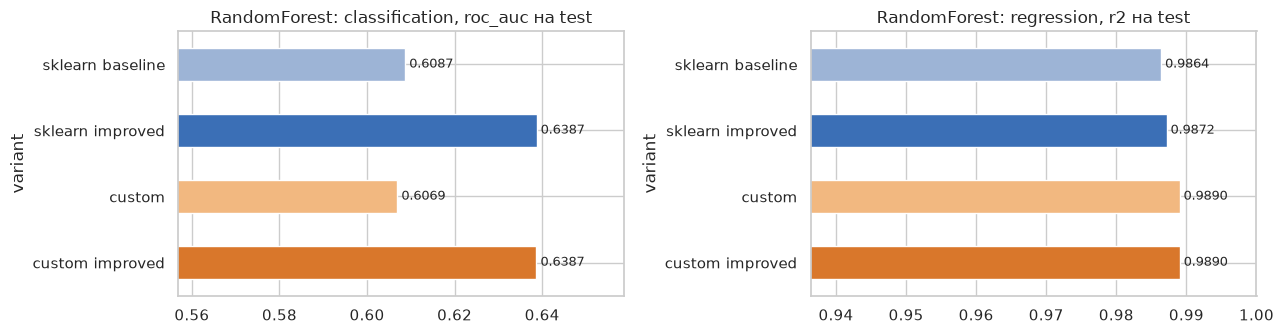

In [15]:
display(log.table("classification"), log.table("regression"))
log.plot()
print("Сохранено:", log.save().relative_to(ROOT))

<!-- lab4_summary -->
**Выводы по ЛР №4.**
1. Случайный лес сильно превосходит одиночное дерево на шумной задаче (ROC-AUC 0.609 против 0.518 у бейзлайнов) за счёт усреднения декоррелированных деревьев.
2. Для Dota 2 главные улучшения — признаки драфта и крупные листья (`min_samples_leaf = 500`): ROC-AUC 0.609 → 0.639; число деревьев выходит на плато после ≈200, `max_features` влияет слабо.
3. Для шахмат случайный лес не лучше одиночного дерева: случайные подпространства признаков вредят (ключевые признаки должны быть доступны в каждом узле), а оптимальная конфигурация — бэггинг полных деревьев.
4. Собственная реализация совпадает с `sklearn` по качеству (с точностью до случайности, что подтверждено экспериментом с несколькими seed); на глубоких деревьях она медленнее, на неглубоких — быстрее.